# Example PRISM Data Loading and Plotting

In [1]:
# cartopy/matplotlib can throw out a lot of warnings - this just cleans things up
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

In [4]:
# load in some packages
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob


# cartopy for plotting gridded maps
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

## 800-meter gridded data

In [13]:
# read in data from csv file as pandas dataframe
# important to skip header

csv_files = glob('../DataJam/PRISM*.csv') # replace with wherever you're storing your data
df = pd.concat((pd.read_csv(file,skiprows=10) for file in csv_files),ignore_index=True) 

# rename to convenient column names
df.columns = df.columns.str.strip()
df = df.rename(columns={
    'Longitude': 'lon',
    'Latitude': 'lat',
    'Elevation (m)': 'elevation_m',
    'Date': 'time',
    'ppt (mm)': 'ppt_mm',
    'tmin (degrees C)': 'tmin_c',
    'tmean (degrees C)': 'tmean_c',
    'tmax (degrees C)': 'tmax_c',
})
# convert time column to datetime object instead of string
df['time'] = pd.to_datetime(df['time'], errors='coerce')

# preview the dataframe
df

,Name,lon,lat,elevation_m,time,ppt_mm,tmin_c,tmean_c,tmax_c
0,Location 1,-90.3764,38.7754,179,2019-01-01,10.23,2.3,5.7,9.0
1,Location 1,-90.3764,38.7754,179,2019-01-02,0.00,-0.6,0.9,2.4
2,Location 1,-90.3764,38.7754,179,2019-01-03,0.00,-3.5,-1.2,1.1
3,Location 1,-90.3764,38.7754,179,2019-01-04,0.00,-4.0,1.9,7.9
4,Location 1,-90.3764,38.7754,179,2019-01-05,0.00,0.4,5.3,10.2
...,...,...,...,...,...,...,...,...,...
1768047,Location 484,-90.0636,38.5306,158,2021-12-27,0.00,5.3,11.5,17.7
1768048,Location 484,-90.0636,38.5306,158,2021-12-28,2.89,5.8,11.5,17.1
1768049,Location 484,-90.0636,38.5306,158,2021-12-29,10.40,2.9,5.4,7.8
1768050,Location 484,-90.0636,38.5306,158,2021-12-30,1.50,2.3,3.4,4.4


In [16]:
# convert to gridded xarray dataset with time, lat, lon as coordinates
ds = df.set_index(['time','lat','lon']).to_xarray().drop('Name').chunk({'time':100,'lat': -1,'lon': -1})

ds

<xarray.Dataset> Size: 71MB
Dimensions:      (time: 3653, lat: 22, lon: 22)
Coordinates:
  * time         (time) datetime64[us] 29kB 2016-01-01 2016-01-02 ... 2025-12-31
  * lat          (lat) float64 176B 38.53 38.54 38.55 ... 38.75 38.76 38.78
  * lon          (lon) float64 176B -90.38 -90.36 -90.35 ... -90.08 -90.06
Data variables:
    elevation_m  (time, lat, lon) int64 14MB dask.array<chunksize=(100, 22, 22), meta=np.ndarray>
    ppt_mm       (time, lat, lon) float64 14MB dask.array<chunksize=(100, 22, 22), meta=np.ndarray>
    tmin_c       (time, lat, lon) float64 14MB dask.array<chunksize=(100, 22, 22), meta=np.ndarray>
    tmean_c      (time, lat, lon) float64 14MB dask.array<chunksize=(100, 22, 22), meta=np.ndarray>
    tmax_c       (time, lat, lon) float64 14MB dask.array<chunksize=(100, 22, 22), meta=np.ndarray>

Text(0.5, 1.0, '2022-07-26 STL Precipitation [mm]')

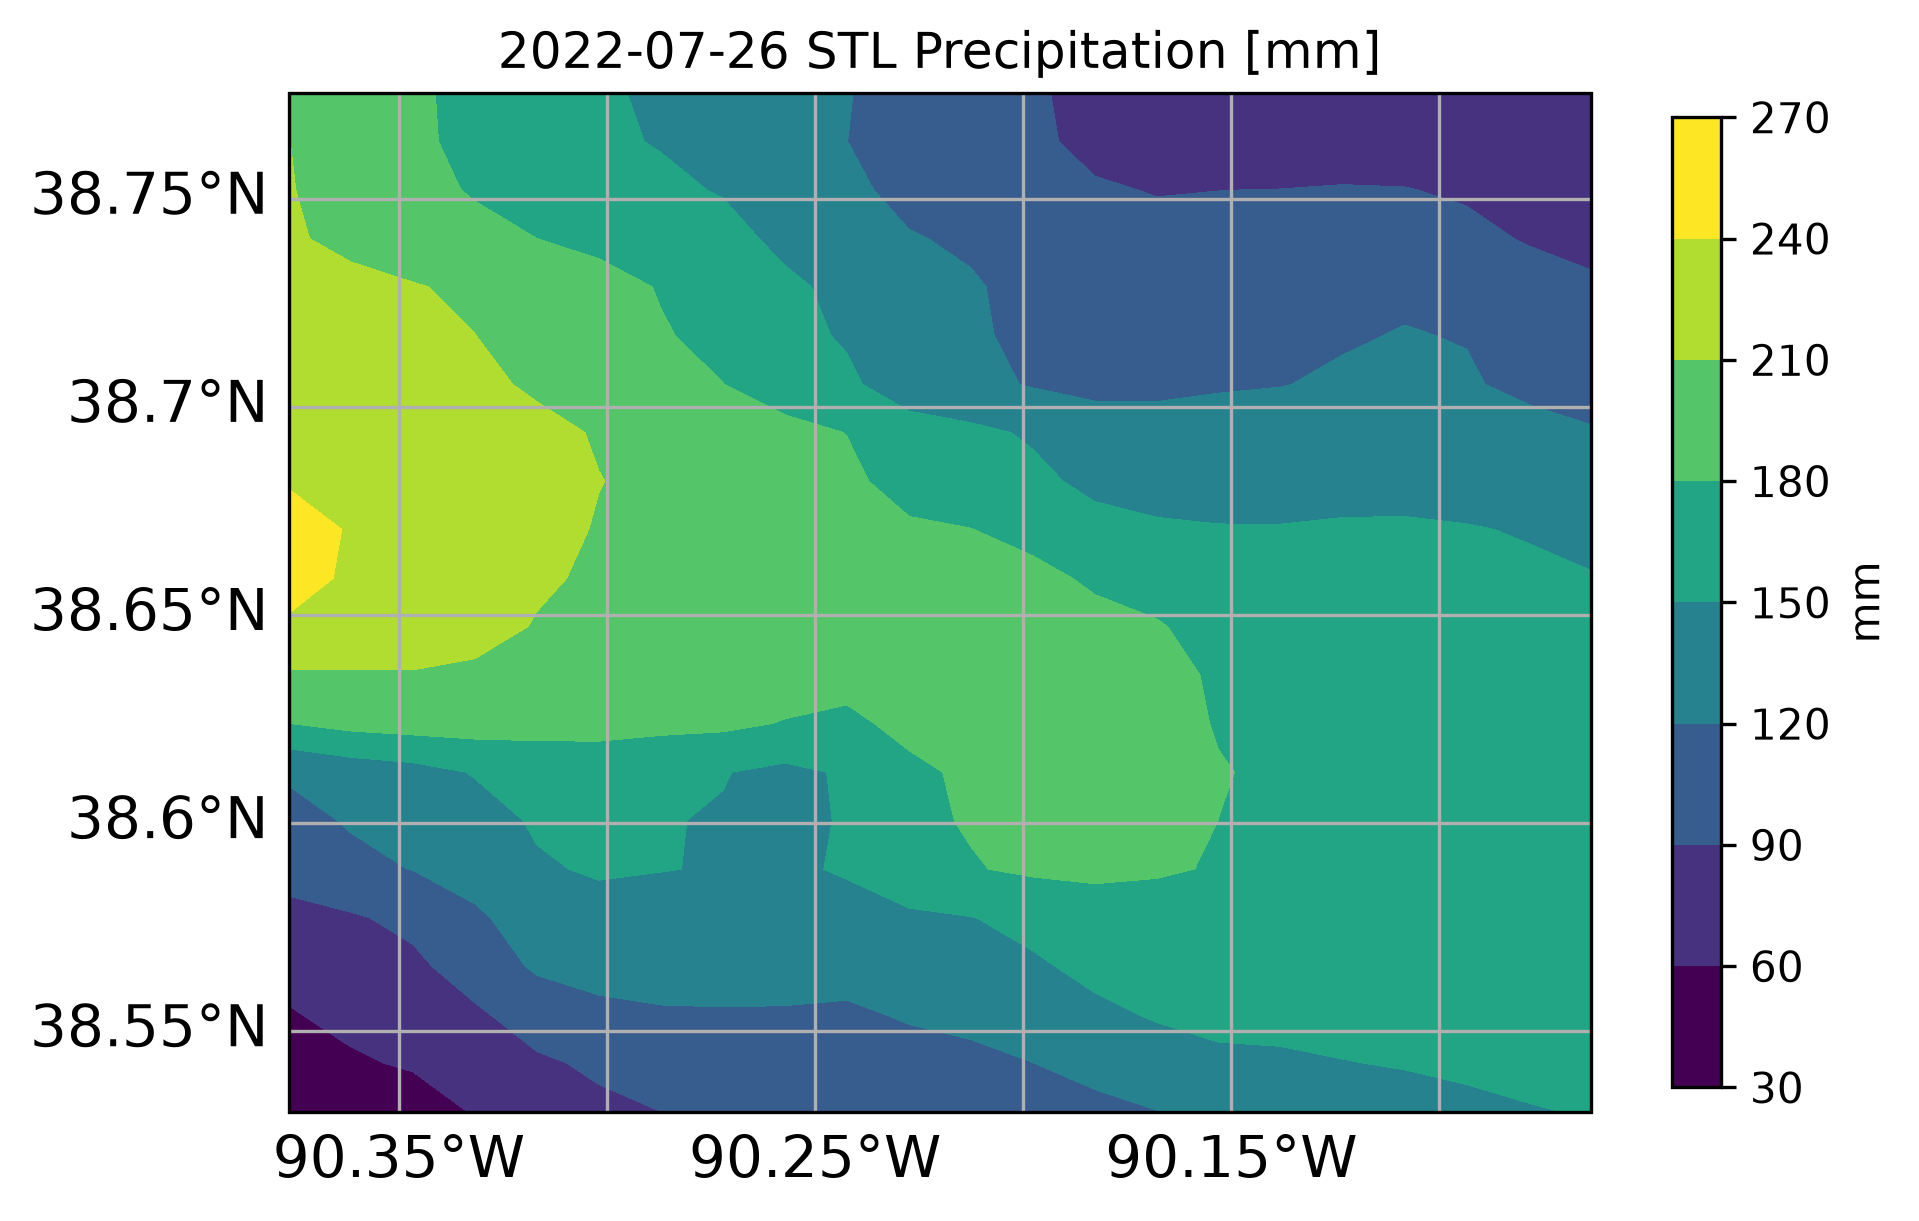

In [26]:
# let's plot a rainy day (jul 26, 2022)

# select for the date and precipitation variable

date = '2022-07-26'
ppt_rainy = ds.ppt_mm.sel(time=date)


# some plotting code - create a figure and geo axes with a flat map projection
fig = plt.figure(figsize=(7,7),dpi=300,)
fig.set_facecolor('white')
ax = fig.add_subplot(1,1,1,projection=ccrs.PlateCarree(central_longitude=0))
ax.grid(visible=True)

# add some nice grid lines with lat/lon formatter
gl = ax.gridlines(draw_labels=True, zorder=3)
gl.top_labels = False
gl.right_labels = False
gl.xformatter = LongitudeFormatter()
gl.yformatter = LatitudeFormatter()
gl.xlines = True
gl.ylines = True
gl.xlabel_style = {'size': 14}
gl.ylabel_style = {'size': 14}

# here's where you plot the data: 
# .plot.contourf() tells it to create filled contours (just use .plot() if you want to see the individual grid cells)
# ax=ax tells it to plot on the geo axes we created earlier
# add_colorbar=False gets rid of the default colorbar (we add our own later)
# transform tells it to plot correctly with the map projection we assigned

fc = ppt_rainy.plot.contourf(ax=ax,add_colorbar=False,transform=ccrs.PlateCarree(central_longitude=0))

# add a colorbar with proper labeling
plt.colorbar(fc,label='mm',shrink=0.6)

# always title your plots!
plt.title(f'{date} STL Precipitation [mm]')

Text(0.5, 1.0, '2022 STL Mean Precipitation [mm]')

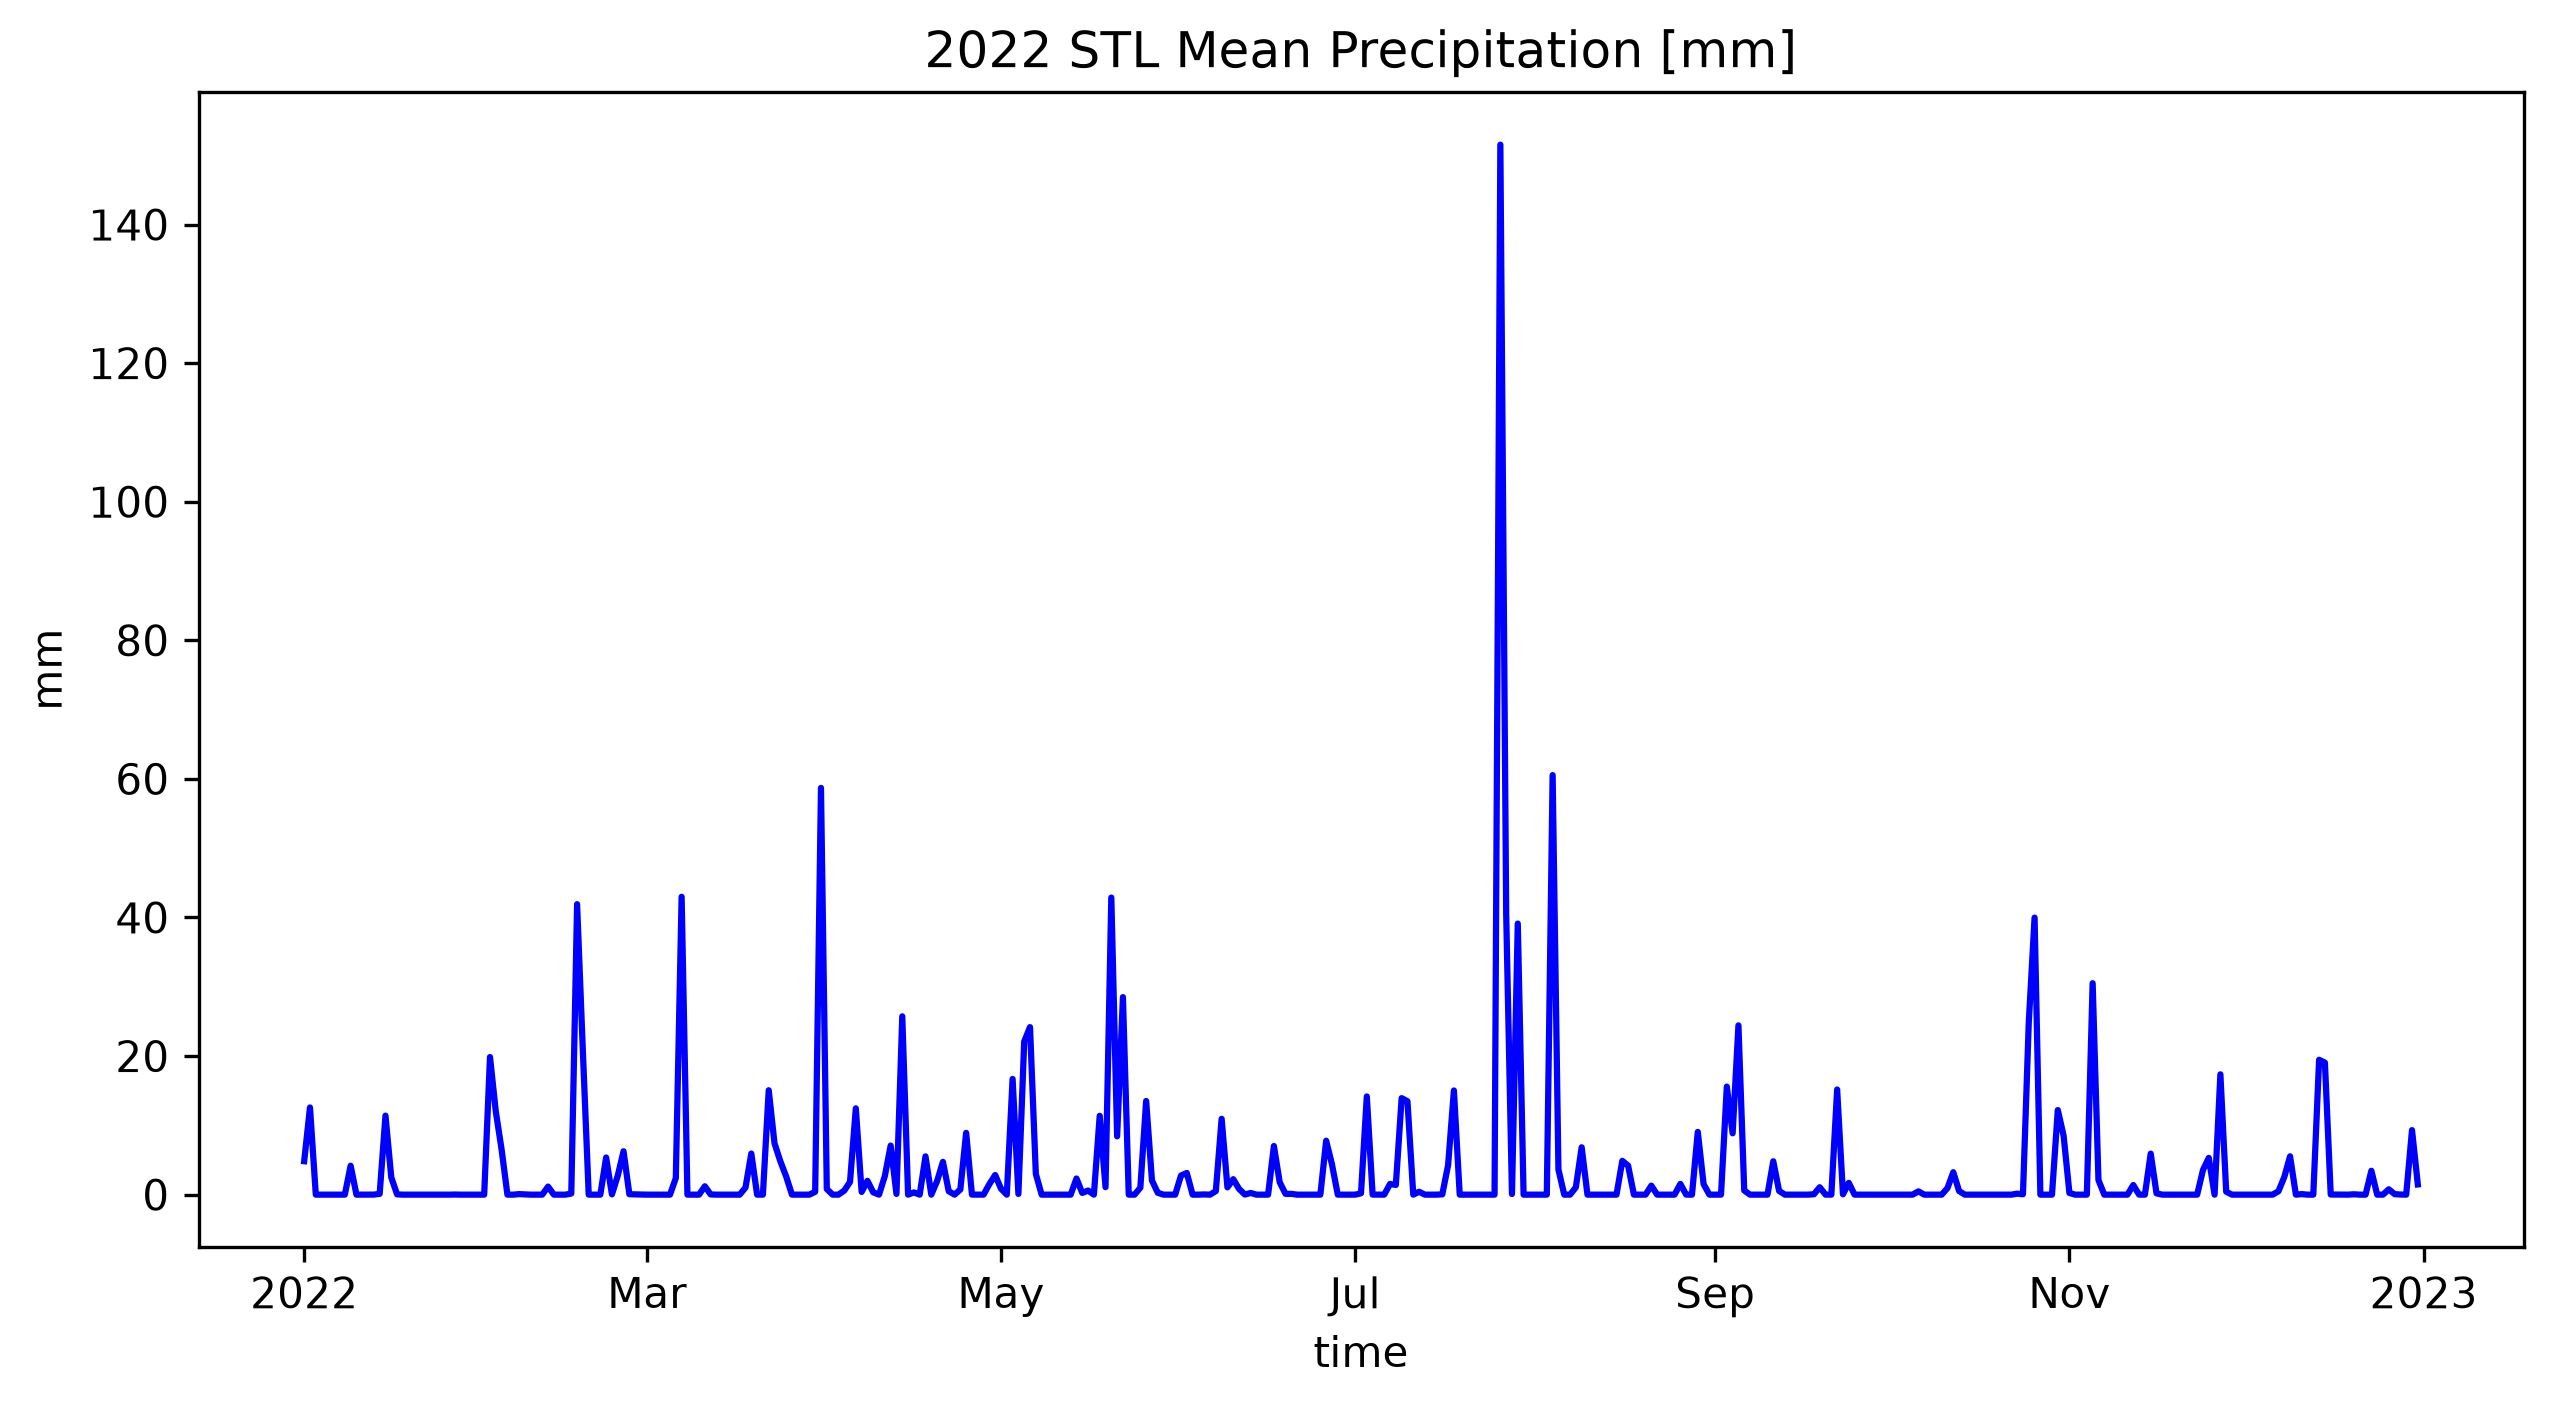

In [40]:
# How about a time series? Zoom in on just 2022

# datetime format makes it easy to select dates by month/year!
ppt_jul22 = ds.sel(time='2022').ppt_mm

# take a mean in the box over latitude/longitude
# NOTE: most proper way to do this would be an area weighted mean with cosine of the latitude
# but with this small of a region it's negligable - try it out for an extra challenge
ppt_jul22_mean = ppt_jul22.mean(['lat','lon'])

 
# some plotting code
fig = plt.figure(figsize=(10,5),dpi=300,)
fig.set_facecolor('white')
ax = fig.add_subplot(1,1,1)

ppt_jul22_mean.plot(color='b')
plt.ylabel('mm')
plt.title('2022 STL Mean Precipitation [mm]')

## Data by zip code

In [43]:
# to save some time, we processed data by zipcode 
# try to do this on your own if you want a challenge!

df = pd.read_csv('stl_prism_zipcode_ppt_2016-2025.csv')

# convert date column to datetime object
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

df

,Date,62025,62040,62059,62060,62071,62090,62201,62203,62204,...,63135,63136,63137,63138,63139,63140,63143,63144,63145,63147
0,2016-01-01,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0
1,2016-01-02,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0
2,2016-01-03,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0
3,2016-01-04,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0
4,2016-01-05,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3648,2025-12-27,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0
3649,2025-12-28,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0
3650,2025-12-29,0.0,0.0,0.0,0.0,0.0,0.0,0.022083,0.0,0.0,...,0.065,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0675,0.0
3651,2025-12-30,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0


Text(0.5, 1.0, '07/2022 STL Mean Precipitation [mm]')

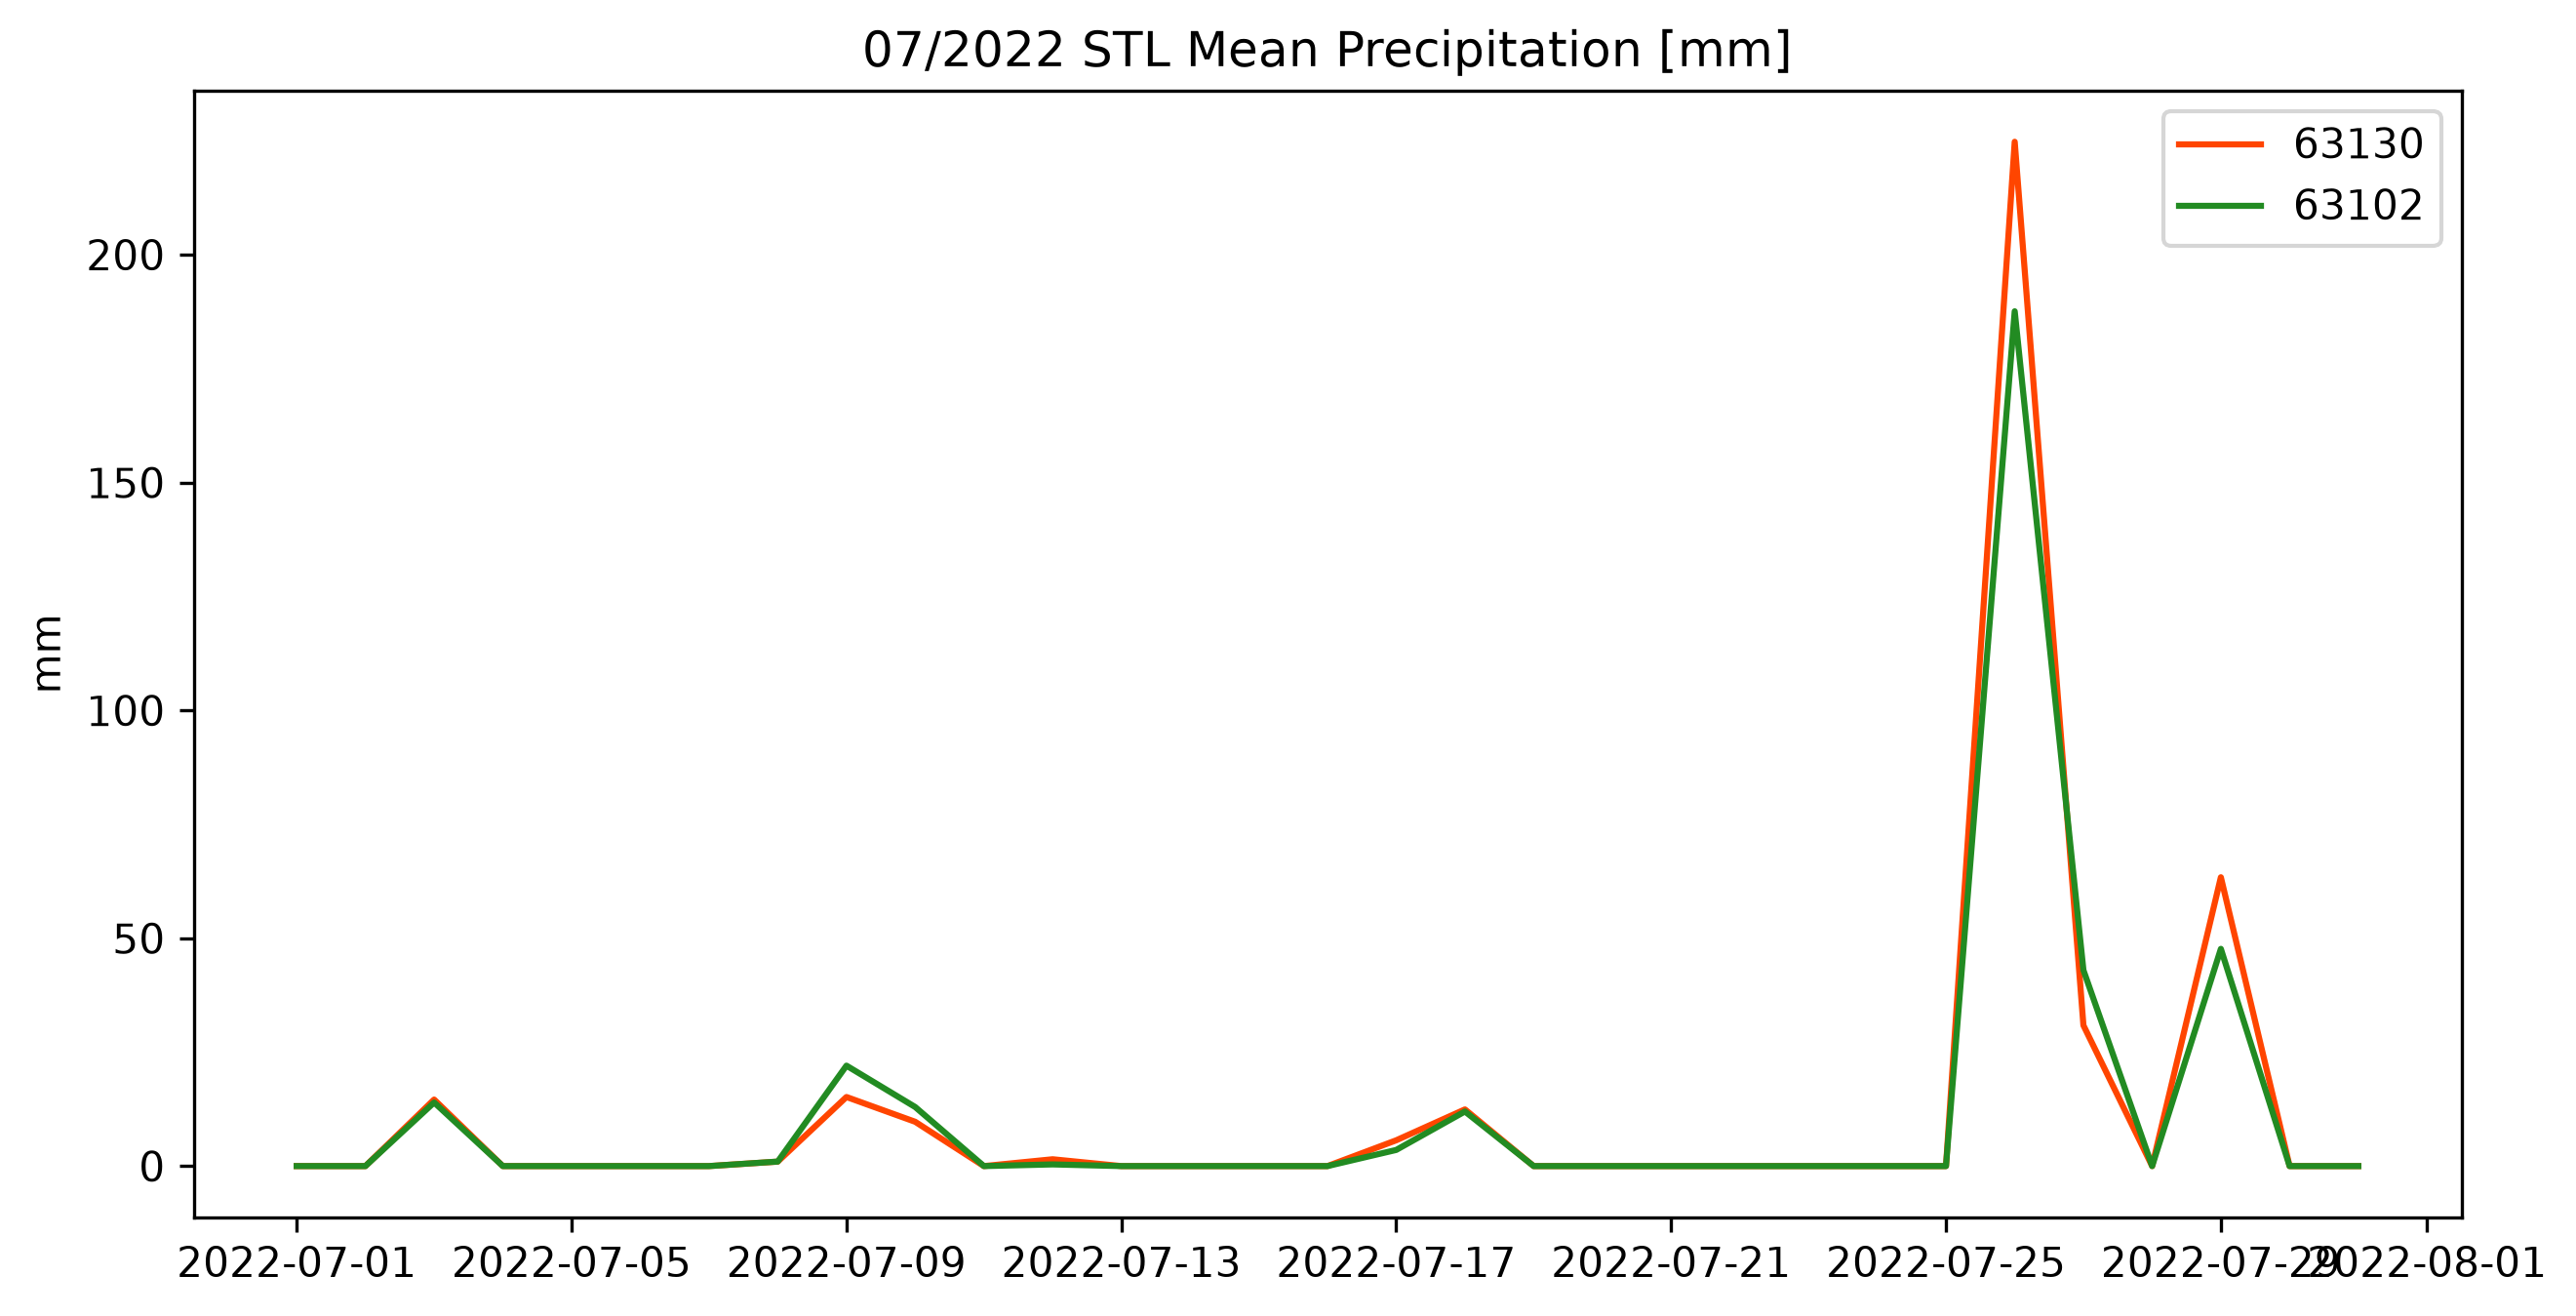

In [59]:
# Let's compare two zip codes: 63130 (Danforth campus) and 63102 (arch)

# select july 2022 using pandas 
ppt_0722 = df.loc[(df['Date'].dt.year==2022) & (df['Date'].dt.month==7)]

fig = plt.figure(figsize=(10,5),dpi=300,)
fig.set_facecolor('white')
ax = fig.add_subplot(1,1,1)

plt.plot(ppt_0722['Date'],ppt_0722['63130'],label='63130',color='orangered')

plt.plot(ppt_0722['Date'],ppt_0722['63102'],label='63102',color='forestgreen')

plt.legend()

plt.ylabel('mm')
plt.title('07/2022 STL Mean Precipitation [mm]')